# UMAP figures and cell statistics (exp_1 + exp_2)

UMAP of the `exp1_86_exp2_all` cell selection of the merged exp_1 + kept-1M exp_2 object (9,991,758 cells: exp_1
without C3a, IL-18, TNF-α, TGF-β1, i.e. 86 cytokines + PBS, and every exp_2 cell incl. TimePoint-0) from
`data/main_screen/HCD_exp_1_exp_2_umap_all.h5ad`,
and the cell statistics plots of `01_umap.ipynb`, computed on these cells. Port of
`fig_1_old/fig_1_00_umap_figures.ipynb` (which used the UMAP of all cells of the previous merged object).

Paths are resolved from the repository root, so the notebook can run from its own folder or the root.
Annotations are loaded from `annotations/`; all figures and separate legends are saved to
`outputs/main_screen/plots/UMAP_overview/`. Only observations and UMAP coordinates are read, without
loading the expression matrix.

* UMAPs are drawn with matplotlib directly (`ax.scatter`, one call per layer), saved as PNG and shown from the
  file (re-rendering 10M points inline would double the time, ~30 s per figure). Each UMAP is saved without
  axes and legend (`<name>.png`) plus its legend as a separate file (`<name>_legend.png`).
* Add `"svg"` (or `"pdf"`) to `FORMATS` for vector files: the point layer is rasterized (`rasterized=True`) at
  `DPI`, everything else (legend, text) stays vector, so an SVG is about as large as the PNG (a few MB)
  instead of hundreds of MB with 10M vector points.
* Categorical colourings are drawn in random cell order, so no category is systematically on top; layered
  figures (experiment, timepoint, PBS) draw the smaller group last, on top.

In [11]:
import io
import os
from pathlib import Path

import h5py
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from anndata.io import read_elem
from IPython.display import Image, display
from matplotlib import font_manager
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image as PILImage
from utils.plotting_utils import cm_to_inches, setup_plotting_environment
setup_plotting_environment()

# Locate the repository from the notebook folder or the repository root.
REPO = Path.cwd().resolve()
REPO = next(path for path in (REPO, *REPO.parents) if (path / "data" / "main_screen").is_dir() and (path / "annotations").is_dir())
UMAP_FILE = REPO / "data" / "main_screen" / "HCD_exp_1_exp_2_umap_all.h5ad"
FIGDIR = REPO / "outputs" / "main_screen" / "plots" / "UMAP_overview"
DONOR_METADATA = REPO / "annotations" / "donor_metadata.xlsx"
CYTOKINE_INFO = REPO / "annotations" / "cytokine_info.xlsx"

FORMATS = ["png", "svg"]   # the UMAP points are rasterized in vector formats
DPI = 300
UMAP_FIGSIZE = (8, 8)      # inches
SIZE_ALL = 0.1             # marker area (pt^2) for layers with ~10M cells
SIZE_TOP = 0.4             # marker area for the PBS cells drawn on top
SIZE_EXP2 = 0.15           # marker area for the exp_2 cells drawn on top (larger points cover exp_1 entirely)
SIZE_T0 = 1.0              # marker area for the 71k timepoint-0 cells
GRAY = "#d9d9d9"
SEED = 0
FS = 6                     # font size of the statistics plots

os.makedirs(FIGDIR, exist_ok=True)
# Arial is not installed on this machine; Liberation Sans has the same metrics
FONT = "Arial" if "Arial" in {f.name for f in font_manager.fontManager.ttflist} else "Liberation Sans"
plt.rcParams["font.family"] = FONT
plt.rcParams["svg.fonttype"] = "none"   # text in SVGs stays editable text
plt.rcParams["pdf.fonttype"] = 42
print("font:", FONT, "| figures:", FIGDIR)

font: Arial | figures: /Users/loesinghaus/Library/CloudStorage/Dropbox/parse_pbmc_data/HumanCytokineDict/outputs/main_screen/plots/UMAP_overview


In [2]:
def replace_greek(x):
    for name, letter in [("alpha", "α"), ("beta", "β"), ("gamma", "γ"), ("lambda", "λ"),
                         ("epsilon", "ε"), ("omega", "ω")]:
        x = x.replace(name, letter)
    return x


# cell type colours of 01_umap.ipynb (fine and coarse names)
celltype_color_mapping = {
    'B cell': "#2278B5",
    'Naive B cell': "#2278B5",
    'Intermediate B cell': "#42B9EB",
    'CD4 T cell': "#F57F20",
    'CD4 Naive T cell': "#F7901E",
    'CD4 Memory T cell': "#F15A22",
    'CD8 T cell': "#2FA148",
    'CD8 Naive T cell': "#2FA148",
    'CD8 Memory T cell': "#17A57F",
    'Treg': "#7750A1",
    'MAIT': "#4C87C6",
    'NKT': "#ED2224",
    'NK CD56hi': "#F9BFCB",
    'NK CD56low': "#8C471F",
    'ILC': "#282A74",
    'pDC': "#ED2A91",
    'cDC': "#6ABD45",
    'CD14 Mono': "#7D277D",
    'CD16 Mono': "#E4C494",
    'HSPC': "#6A6A6A",
    "Granulocyte": "#FDD700",
    "Plasmablast": "#556B30",
    "Platelet": '#d9d9d9',
}
CELLTYPE_ORDER = [
    'Intermediate B cell', 'Naive B cell', 'CD4 Naive T cell', 'CD4 Memory T cell', 'CD8 Naive T cell',
    'CD8 Memory T cell', 'Treg', 'MAIT', 'NKT', 'NK CD56hi', 'NK CD56low', 'pDC', 'cDC', 'CD14 Mono',
    'CD16 Mono', 'HSPC', 'ILC', 'Granulocyte', 'Plasmablast', 'Platelet',
]
EXPERIMENT_COLORS = {"exp_1": "#4C87C6", "exp_2": "#F57F20"}
TIMEPOINT_COLORS = {"24h": "#4C87C6", "0h": "#ED2224"}
DONOR_ORDER = [f"Donor{i}" for i in range(1, 13)]
# 12 distinct colours without gray (gray is the background of the PBS figures)
DONOR_COLORS = dict(zip(DONOR_ORDER, [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b",
    "#e377c2", "#bcbd22", "#17becf", "#aec7e8", "#ffbb78", "#98df8a"]))
SEX_COLORS = {"Female": "#4EB265", "Male": "#CAE0AB"}   # bokeh TolRainbow[13][6, 8], as in 01_umap.ipynb
# cytokine family colours of 01_umap.ipynb (bokeh Category20[20] = matplotlib tab20)
_c20 = [matplotlib.colors.to_hex(c) for c in plt.get_cmap("tab20").colors]
FAMILY_COLORS = {
    'PBS': _c20[14], 'IL-1': _c20[0], 'IL-4/IL-13': _c20[1], 'IL-6': _c20[2], 'IL-10': _c20[3],
    'IL-12': _c20[4], 'IL-17': _c20[5], 'Common γ chain': _c20[6], 'Common β chain': _c20[7],
    'Interferon': _c20[8], 'Growth factor': _c20[9], 'TNF': _c20[10], 'TGF-b': _c20[11],
    'Complement': _c20[12], 'Other': _c20[13],
}

## Data

In [12]:
with h5py.File(UMAP_FILE, "r") as f:
    obs = read_elem(f["obs"])
    XY = read_elem(f["obsm"]["X_umap"])
for col, order in [("cell_type", CELLTYPE_ORDER), ("donor", DONOR_ORDER),
                   ("experiment", ["exp_1", "exp_2"]), ("timepoint", ["0h", "24h"])]:
    assert set(obs[col].astype(str)) <= set(order), (col, set(obs[col].astype(str)) - set(order))
    obs[col] = pd.Categorical(obs[col].astype(str), categories=order)
obs["cell_type_coarse"] = obs["cell_type_coarse"].astype("category")
assert XY.shape == (len(obs), 2)
print(f"{len(obs):,} cells")
print(pd.crosstab(obs.treatment, [obs.experiment, obs.timepoint]))

# all UMAPs share the same axis limits, so that panels can be overlaid / aligned
_pad = 0.01 * (XY.max(0) - XY.min(0))
XLIM, YLIM = (XY[:, 0].min() - _pad[0], XY[:, 0].max() + _pad[0]), (XY[:, 1].min() - _pad[1], XY[:, 1].max() + _pad[1])

ALL = np.arange(len(obs))
NO_T0 = np.flatnonzero(obs.timepoint.to_numpy() != "0h")
rows = lambda mask, within=ALL: within[np.asarray(mask)[within]]

9,991,758 cells
experiment     exp_1  exp_2        
timepoint        24h     0h     24h
treatment                          
PBS           629701      0   42377
cytokine     8681876      0  322151
antibody           0      0  101430
combination        0      0  143350
baseline           0  70873       0


### Plotting helpers

In [21]:
RNG = np.random.default_rng(SEED)


def save(fig, name):
    for fmt in FORMATS:
        fig.savefig(FIGDIR / f"{name}.{fmt}", dpi=DPI, bbox_inches="tight", pad_inches=0, transparent=True)
    return FIGDIR / f"{name}.png"


def layer(r, col=None, palette=None, color=None, s=SIZE_ALL, shuffle=True, label=None):
    """One scatter call: cells `r` (row positions) coloured by categorical `col` with `palette`, or all in
    `color`. Drawn in random order unless shuffle=False."""
    return dict(r=np.asarray(r), col=col, palette=palette, color=color, s=s, shuffle=shuffle, label=label)


def _draw(ax, r, col, palette, color, s, shuffle, label):
    if shuffle:
        r = RNG.permutation(r)
    kw = dict(s=s, lw=0, rasterized=True)
    if col is None:
        ax.scatter(XY[r, 0], XY[r, 1], color=color, **kw)
        return {label: color} if label else {}
    cats = list(obs[col].cat.categories)
    codes = obs[col].cat.codes.to_numpy()[r]
    ax.scatter(XY[r, 0], XY[r, 1], c=codes, cmap=ListedColormap([palette.get(c, GRAY) for c in cats]),
               vmin=-0.5, vmax=len(cats) - 0.5, **kw)
    present = set(np.unique(codes))
    return {c: palette.get(c, GRAY) for i, c in enumerate(cats) if i in present}


def preview(png, width=800):
    """Downscaled copy for the notebook (the full PNGs would make the notebook ~60 MB)."""
    im = PILImage.open(png)
    im.thumbnail((2 * width, width))   # at most `width` px high (split figures are twice as wide)
    buf = io.BytesIO()
    im.save(buf, format="PNG")
    return Image(data=buf.getvalue())


def legend_figure(entries, title, markersize=5, ncol=1):
    fig = plt.figure(figsize=(0.1, 0.1))
    handles = [Line2D([], [], marker="o", ls="", color=c, markersize=markersize, label=l) for l, c in entries.items()]
    fig.legend(handles=handles, title=title, loc="center", frameon=False, fontsize=6, title_fontsize=6,
               ncol=ncol, handletextpad=0.2, alignment="left")
    return fig


def umap_figure(name, layers, legend_title=None, legend_order=None, legend_extra=None, panels=None):
    """Draws `layers` (or one list of layers per panel), saves <name>.<fmt> without axes/legend and the legend as
    <name>_legend.<fmt>; shows both."""
    panels = panels or [(None, layers)]
    fig, axes = plt.subplots(1, len(panels), figsize=(UMAP_FIGSIZE[0] * len(panels), UMAP_FIGSIZE[1]), squeeze=False,
                             gridspec_kw={"wspace": 0.02})
    fig.subplots_adjust(left=0, right=1, bottom=0, top=0.97 if any(t for t, _ in panels) else 1)
    entries = {}
    for ax, (title, panel_layers) in zip(axes[0], panels):
        for l in panel_layers:
            entries.update(_draw(ax, **l))
        ax.set_xlim(XLIM), ax.set_ylim(YLIM)
        ax.set_aspect("equal")
        ax.set_axis_off()
        if title:
            ax.set_title(title, fontsize=6, loc="left")
    png = save(fig, name)
    plt.close(fig)
    if legend_order is not None:
        entries = {k: entries[k] for k in legend_order if k in entries}
    entries.update(legend_extra or {})
    fig_l = legend_figure(entries, legend_title)
    png_l = save(fig_l, f"{name}_legend")
    plt.close(fig_l)
    display(preview(png), Image(str(png_l)))
    print(f"{name}: " + ", ".join(f"{sum(len(l['r']) for l in p):,} cells" for _, p in panels))


def umap_celltype_overview(selected, name="umap_90_cytokines_celltype", label_offsets=None):
    label_offsets = label_offsets or {}
    selected = np.asarray(selected)
    categories = obs["cell_type"].cat.categories
    codes = obs["cell_type"].cat.codes.to_numpy()[selected]
    counts = pd.Series(np.bincount(codes[codes >= 0], minlength=len(categories)), index=categories)
    order = ["Naive B cell", "Intermediate B cell"] + [c for c in CELLTYPE_ORDER if c not in ["Naive B cell", "Intermediate B cell"]]
    order = [c for c in order if counts.get(c, 0) > 0]

    # Compute exact medians one cell type at a time, before allocating the scatter plot.
    centers = {}
    for celltype in order:
        cell_rows = selected[codes == categories.get_loc(celltype)]
        centers[celltype] = np.median(XY[cell_rows], axis=0)
    del codes, cell_rows

    fig, (ax, ax_legend) = plt.subplots(1, 2, figsize=cm_to_inches((10.5, 7)), gridspec_kw={"width_ratios": [2.1, 1], "wspace": 0.03})
    fig.subplots_adjust(left=0.02, right=0.99, bottom=0.04, top=0.99)

    # Small, translucent points, drawn in random order.
    _draw(ax, **layer(selected, "cell_type", celltype_color_mapping, s=0.05))
    ax.collections[-1].set_alpha(0.2)
    ax.set_xlim(XLIM)
    ax.set_ylim(YLIM)
    ax.set_aspect("equal")
    ax.set_axis_off()

    # Exact median positions provide starting locations for the cluster labels.
    labels = {c: c.replace(" T cell", "\nT cell") for c in order}
    labels.update({"Intermediate B cell": "Intermediate\nB cell", "CD16 Mono": "CD16\nMono", "Granulocyte": "Gran."})

    for celltype in order:
        x, y = centers[celltype]
        offset = label_offsets.get(celltype, (0, 0))
        ax.annotate(labels[celltype], xy=(x, y), xytext=offset, textcoords="offset points", ha="center", va="center", fontsize=6, fontweight="bold", annotation_clip=False, zorder=5)

    # Decorative arrows indicating the existing UMAP coordinate directions.
    arrow_style = dict(arrowstyle="-|>", color="black", lw=2, mutation_scale=15)
    ax.annotate("", xy=(0.17, 0.06), xytext=(0.04, 0.06), xycoords="axes fraction", arrowprops=arrow_style)
    ax.annotate("", xy=(0.04, 0.19), xytext=(0.04, 0.06), xycoords="axes fraction", arrowprops=arrow_style)
    ax.text(0.105, 0.035, "UMAP1", transform=ax.transAxes, ha="center", va="top", fontsize=6)
    ax.text(0.015, 0.125, "UMAP2", transform=ax.transAxes, ha="right", va="center", rotation=90, fontsize=6)

    # Square legend swatches and counts calculated from the selected cells.
    ax_legend.set_axis_off()
    handles = [Patch(facecolor=celltype_color_mapping[c], edgecolor="none", label=f"{c} ({counts[c] / 1000:.0f}k)" if counts[c] >= 1000 else f"{c} ({counts[c]:,})") for c in order]
    ax_legend.legend(handles=handles, loc="upper left", frameon=False, prop={"size": 6, "weight": "bold"}, handlelength=1, handleheight=1, handletextpad=0.5, labelspacing=0.65)
    ax_legend.text(0.03, 0.02, f"n = {len(selected):,} cells", transform=ax_legend.transAxes, fontsize=6, fontweight="bold")

    png = save(fig, name)
    plt.close(fig)
    display(preview(png, width=1200))

## UMAPs: all cells

Colored by experiment: exp_2 (680k cells) drawn on top of exp_1 (9.7M), with slightly larger points. The second figure shows
each experiment on its own over the other in gray, so both are visible where they overlap.

In [ ]:
is_exp2 = obs.experiment.to_numpy() == "exp_2"
umap_figure(
    "umap_all_experiment",
    [layer(rows(~is_exp2), "experiment", EXPERIMENT_COLORS),
     layer(rows(is_exp2), "experiment", EXPERIMENT_COLORS, s=SIZE_EXP2)],
    legend_title="Experiment", legend_order=["exp_1", "exp_2"])

In [18]:
# umap_figure(
#     "umap_all_experiment_split", None, legend_title="Experiment", legend_order=["exp_1", "exp_2"],
#     panels=[
#         ("exp_1", [layer(rows(is_exp2), color=GRAY, s=SIZE_EXP2),
#                    layer(rows(~is_exp2), "experiment", EXPERIMENT_COLORS)]),
#         ("exp_2", [layer(rows(~is_exp2), color=GRAY),
#                    layer(rows(is_exp2), "experiment", EXPERIMENT_COLORS, s=SIZE_EXP2)]),
#     ])

In [ ]:
# umap_figure("umap_all_celltype", [layer(ALL, "cell_type", celltype_color_mapping)],
#             legend_title="Cell type", legend_order=CELLTYPE_ORDER)

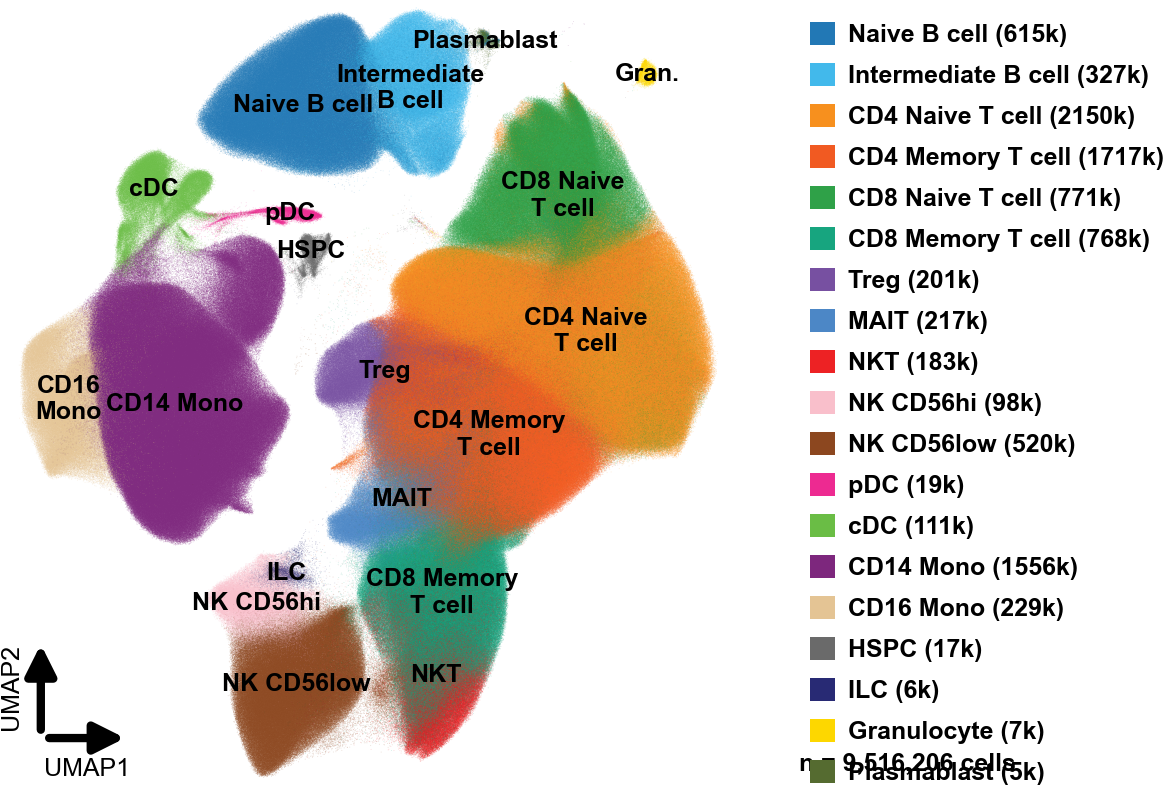

In [22]:
exp2_cytokines = ["C3a", "IL-18", "TNF-alpha", "TGF-beta1"]

# PBS + 86 cytokines from exp_1; the remaining 4 cytokines from exp_2.
mask = (obs.experiment.eq("exp_1") & ~obs.cytokine.isin(exp2_cytokines)) | (obs.experiment.eq("exp_2") & obs.cytokine.isin(exp2_cytokines + ["PBS"]))
mask &= obs.timepoint.eq("24h") & obs.treatment.isin(["PBS", "cytokine"])
mask &= obs.cell_type.ne("Platelet")
selected = rows(mask)

# Optional label adjustments in points: (horizontal, vertical).
label_offsets = {}

umap_celltype_overview(selected, label_offsets=label_offsets)

## Cell statistics

The statistics plots of `01_umap.ipynb` on all cells of this UMAP (the `exp1_86_exp2_all` selection, both
timepoints), except
the cytokine distribution, which uses exp_1 only (exp_2 has antibody / combination treatments without a cytokine
family). Set `STATS` to e.g. `obs[obs.experiment == "exp_1"]` to restrict all of them.

In [23]:
STATS = obs
GAR = 1.61803398875   # golden aspect ratio
donor_to_sex = dict(pd.read_excel(DONOR_METADATA)[["Donor number", "Sex"]].values)
donor_label = lambda d: d.replace("Donor", "Donor ")
print(f"{len(STATS):,} cells")

def savefig(name):
    for fmt in FORMATS:
        plt.savefig(FIGDIR / f"{name}.{fmt}", dpi=DPI, pad_inches=0, bbox_inches="tight", transparent=True)

9,991,758 cells


### % PBS-treated cells per cell type

cell_type,Intermediate B cell,Naive B cell,CD4 Naive T cell,CD4 Memory T cell,CD8 Naive T cell,CD8 Memory T cell,Treg,MAIT,NKT,NK CD56hi,NK CD56low,pDC,cDC,CD14 Mono,CD16 Mono,HSPC,ILC,Granulocyte,Plasmablast
pct,6.69,6.81,6.55,6.62,6.48,6.56,6.28,6.89,6.67,6.47,6.7,6.84,6.43,7.27,7.37,6.25,6.37,6.37,6.92


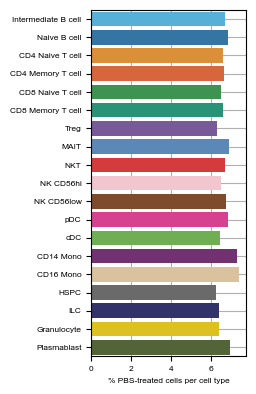

In [24]:
n_pbs = STATS.loc[STATS.cytokine.astype(str) == "PBS", "cell_type"].value_counts()
n_all = STATS.cell_type.value_counts()
frac_cells_pbs = (n_pbs / n_all * 100).rename("pct").reindex(CELLTYPE_ORDER[:-1]).reset_index()   # w/o Platelet
display(frac_cells_pbs.set_index("cell_type").round(2).T)

fig, ax = plt.subplots(1, 1, figsize=(2, 4.5))
sns.barplot(data=frac_cells_pbs, y="cell_type", x="pct", hue="cell_type", palette=celltype_color_mapping,
            order=CELLTYPE_ORDER[:-1], ax=ax)
ax.set_ylabel("")
ax.set_xlabel("% PBS-treated cells per cell type", fontsize=FS)
ax.tick_params(labelsize=FS)
ax.grid()
ax.set_axisbelow(True)
savefig("stats_frac_pbs_per_celltype")
plt.show()

### Number of cells per donor

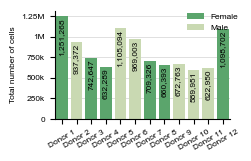

In [26]:
_df_sex = STATS.donor.value_counts().reindex(DONOR_ORDER).rename("count").reset_index()
_df_sex["donor"] = _df_sex["donor"].astype(str).map(donor_label)
_df_sex["sex"] = _df_sex["donor"].map(donor_to_sex)
assert _df_sex["sex"].notna().all()
ymax = _df_sex["count"].max()
ticks = [t for t in [0, 250_000, 500_000, 750_000, 1_000_000, 1_250_000, 1_500_000] if t <= ymax * 1.05]
ticklabels = [f"{t / 1e6:g}M" if t >= 1e6 else (f"{t // 1000}k" if t else "0") for t in ticks]
offset = 0.015 * ymax

fig, ax = plt.subplots(1, 1, figsize=(GAR * 1.4, 1.4))
sns.barplot(_df_sex, x="donor", y="count", hue="sex", palette=SEX_COLORS, order=_df_sex.donor, ax=ax)
for p in ax.patches:
    if p.get_height() > 0:
        ax.text(p.get_x() + p.get_width() / 2., p.get_height() - offset, f"{int(p.get_height()):,}",
                ha="center", va="top", fontsize=FS, rotation=90)
ax.spines[["right", "top"]].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("Total number of cells", fontsize=FS)
ax.legend(frameon=False, fontsize=FS, loc="upper center", bbox_to_anchor=(0.9, 1.05))
ax.grid(axis="y", linewidth=0.5, color="lightgray")
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=FS, rotation=30)
ax.set_yticks(ticks, ticklabels, fontsize=FS)
savefig("stats_cells_per_donor")
plt.show()

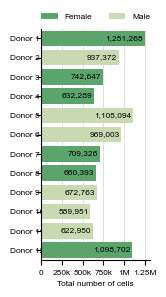

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(1.4, 3))
sns.barplot(_df_sex, y="donor", x="count", hue="sex", palette=SEX_COLORS, order=_df_sex.donor, ax=ax)
for p in ax.patches:
    if p.get_width() > 0:
        ax.text(p.get_width() - offset, p.get_y() + p.get_height() / 2, f"{int(p.get_width()):,}",
                ha="right", va="center", fontsize=FS)
ax.spines[["right", "top"]].set_visible(False)
ax.set_ylabel("")
ax.set_xlabel("Total number of cells", fontsize=FS)
ax.legend(frameon=False, fontsize=FS, loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=2)
ax.grid(axis="x", linewidth=0.5, color="lightgray")
ax.set_axisbelow(True)
ax.tick_params(axis="y", labelsize=FS)
for label in ax.get_yticklabels():
    label.set_horizontalalignment("left")
    label.set_x(-0.2)
ax.set_xticks(ticks, ticklabels, fontsize=FS)
savefig("stats_cells_per_donor_vertical")
plt.show()

### Number of cells per cell type

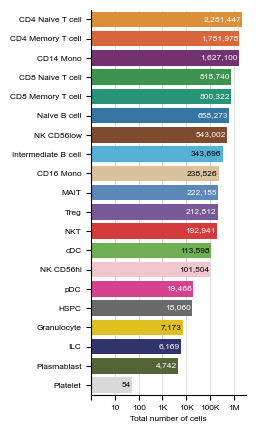

In [29]:
_df_ct = STATS.cell_type.value_counts()
_df_ct = _df_ct[_df_ct > 0].rename("count").reset_index()
_df_ct["cell_type"] = _df_ct["cell_type"].astype(str)


def label_color(patch):
    r, g, b = patch.get_facecolor()[:3]
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.6 else "black"


fig, ax = plt.subplots(1, 1, figsize=(2, (len(_df_ct) / 12) * 3))
sns.barplot(_df_ct, y="cell_type", x="count", hue="cell_type", palette=celltype_color_mapping,
            order=_df_ct.cell_type, ax=ax)
for p in ax.patches:
    if p.get_width() > 0:
        ax.text(0.9 * p.get_width(), p.get_y() + p.get_height() / 2., f"{int(p.get_width()):,}",
                ha="right", va="center", fontsize=FS, color=label_color(p))
ax.spines[["right", "top"]].set_visible(False)
ax.set_ylabel("")
ax.set_xlabel("Total number of cells", fontsize=FS)
ax.grid(axis="x", linewidth=0.5, color="lightgray")
ax.set_axisbelow(True)
ax.set_xscale("log")
ax.tick_params(axis="y", labelsize=FS)
LOG_TICKS = ([10**k for k in range(0, 8)], ["", "10", "100", "1K", "10K", "100K", "1M", "10M"])
ax.set_xticks(*LOG_TICKS, fontsize=FS)
ax.set_xlim(1, _df_ct["count"].max() * 1.5)
savefig("stats_cells_per_celltype")
plt.show()

### % cells per cell type and donor (with cells per donor and per cell type)

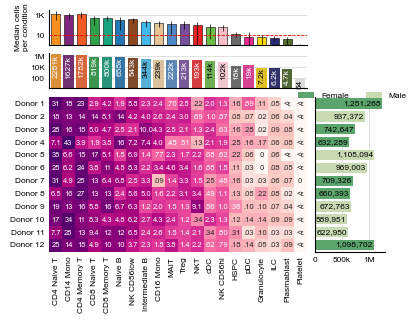

In [57]:
_df_pivot = pd.crosstab(STATS.donor, STATS.cell_type).reindex(index=DONOR_ORDER)
_df_pivot = _df_pivot.loc[:, _df_pivot.sum(axis=0) > 0]
_df_pivot.columns = _df_pivot.columns.astype(str)
_df_pivot_frac = _df_pivot.div(_df_pivot.sum(axis=1), axis=0) * 100
IS_ZERO = 1e-20
_df_pivot_frac[_df_pivot_frac == 0] = IS_ZERO
order = _df_pivot_frac.mean(axis=0).sort_values(ascending=False).index
_df_pivot_frac = _df_pivot_frac.loc[:, order]
_df_pivot_frac.index = _df_pivot_frac.index.astype(str).map(donor_label)

def annot_fn(x):
    if x >= 10:
        return f"{x:.0f}"
    elif x >= 1:
        return f"{x:.1f}"
    elif x == IS_ZERO:
        return "0"
    elif x > 0.1:
        return f"{x:.2f}".replace("0.", ".")
    elif x > 0.01:
        return f"{x:.2f}".replace("0.", ".")
    else:
        return "<ε"
    
annot_labels = _df_pivot_frac.map(annot_fn)

vmin = 1e-2
vmax = _df_pivot_frac.max().max()
cmap = "RdPu"

grid = sns.JointGrid(height=3.5)
sns.heatmap(_df_pivot_frac, square=True, cmap=cmap, norm=LogNorm(vmin=vmin, vmax=vmax), ax=grid.ax_joint,
            annot=annot_labels, annot_kws={"fontsize": 5.5}, fmt="", cbar=False)
grid.ax_joint.set_ylabel("")
grid.ax_joint.set_xlabel("")
grid.ax_joint.tick_params(labelsize=FS)
grid.ax_joint.yaxis.set_tick_params(rotation=0)

# right margin: cells per donor (same donor order as the heatmap rows)
sns.barplot(_df_sex, y="donor", x="count", hue="sex", palette=SEX_COLORS, order=_df_pivot_frac.index,
            ax=grid.ax_marg_y)
_off = 0.5
_ymin, _ymax = grid.ax_joint.get_ylim()
grid.ax_joint.set_ylim(_ymin + _off, _ymax + _off)
for container in grid.ax_marg_y.containers:
    for bar in container:
        bar.set_y(bar.get_y() + _off)
for p in grid.ax_marg_y.patches:
    if p.get_width() > 0:
        grid.ax_marg_y.text(p.get_width() - offset, p.get_y() + p.get_height() / 2, f"{int(p.get_width()):,}",
                            ha="right", va="center", fontsize=FS)
grid.ax_marg_y.legend(frameon=False, fontsize=FS, loc="upper center", bbox_to_anchor=(0.53, 1.08), ncol=2)
grid.ax_marg_y.spines[["right", "top"]].set_visible(False)
grid.ax_marg_y.spines[["left", "bottom"]].set_visible(True)
grid.ax_marg_y.set_ylabel("")
grid.ax_marg_y.set_xlabel("Total number of cells", fontsize=FS)
grid.ax_marg_y.grid(axis="x", linewidth=0.5, color="lightgray")
grid.ax_marg_y.set_axisbelow(True)
grid.ax_marg_y.tick_params(axis="x", which="both", bottom=True, labelbottom=True)
grid.ax_marg_y.set_xticks(ticks[::2], ticklabels[::2], fontsize=FS)   # every other tick: narrow axis
grid.ax_marg_y.tick_params(axis="y", which="both", left=False, labelleft=False)
grid.ax_marg_y.set_position([grid.ax_joint.get_position().x1 + 0.025, grid.ax_joint.get_position().y0,
                             0.2, grid.ax_joint.get_position().height])

# top margin: cells per cell type (same order as the heatmap columns)
sns.barplot(_df_ct, x="cell_type", y="count", hue="cell_type", palette=celltype_color_mapping,
            order=_df_pivot_frac.columns, ax=grid.ax_marg_x)
_xmin, _xmax = grid.ax_joint.get_xlim()
grid.ax_joint.set_xlim(_xmin + _off, _xmax + _off)
for container in grid.ax_marg_x.containers:
    for bar in container:
        bar.set_x(bar.get_x() + _off)
grid.ax_marg_x.set_position([grid.ax_joint.get_position().x0, grid.ax_joint.get_position().y1 + 0.025,
                             grid.ax_joint.get_position().width, 0.2])
for p in grid.ax_marg_x.patches:
    if p.get_height() > 0:
        value = p.get_height()
        label = f"{value:.0f}" if value < 1000 else (f"{value / 1000:.1f}k" if value < 10000 else f"{value / 1000:.0f}k")
        grid.ax_marg_x.text(p.get_x() + p.get_width() / 2., 0.9 * p.get_height(), label,
                            ha="center", va="top", fontsize=FS, color=label_color(p), rotation=90)
grid.ax_marg_x.tick_params(axis="y", which="both", left=True, labelleft=True)
grid.ax_marg_x.spines[["right", "top"]].set_visible(False)
grid.ax_marg_x.spines[["left", "bottom"]].set_visible(True)
grid.ax_marg_x.set_ylabel("Total number of cells", fontsize=FS)
grid.ax_marg_x.grid(axis="y", linewidth=0.5, color="lightgray")
grid.ax_marg_x.set_axisbelow(True)
grid.ax_marg_x.set_yscale("log")

LOG_TICKS = ([10**(2*k) for k in range(0, 4)], ["", "100", "10K", "1M"])
grid.ax_marg_x.set_yticks(*LOG_TICKS, fontsize=FS)
grid.ax_marg_x.set_ylim(1, _df_ct["count"].max() * 1.5)

# Cell counts per fine cell type, cytokine, and donor.
per_condition = STATS.groupby(["cell_type", "cytokine", "donor"], observed=True).size()
g = per_condition.groupby(level="cell_type", observed=True)
median_counts = g.median().reindex(_df_pivot_frac.columns)
count_deviation = g.apply(lambda s: np.mean(np.abs(s - s.median()))).reindex(_df_pivot_frac.columns)

# Add another barplot above the existing total-cell-count barplot.
top_position = grid.ax_marg_x.get_position()
ax_median = grid.figure.add_axes([top_position.x0, top_position.y1 + 0.10, top_position.width, 0.16], sharex=grid.ax_joint)

x = np.arange(len(median_counts)) + 0.5
colors = [celltype_color_mapping[c] for c in median_counts.index]
ax_median.bar(x, median_counts.values - 1, bottom=1, yerr=count_deviation.values, color=colors,
    edgecolor="black", linewidth=0.4, width=0.7, ecolor="black", error_kw={"elinewidth": 0.5}, capsize=0)

ax_median.set_yscale("log")
ax_median.set_ylim(bottom=1)
ax_median.axhline(10, color="red", linestyle="--", linewidth=0.6)
ax_median.set_ylabel("Median cells\nper condition", fontsize=FS)
ax_median.spines[["right", "top"]].set_visible(False)
ax_median.grid(axis="y", linewidth=0.5, color="lightgray")
ax_median.set_axisbelow(True)
ax_median.tick_params(axis="x", which="both", labelbottom=False)
ax_median.tick_params(axis="y", labelsize=FS)
ax_median.set_yticks([10, 1000], labels=["10", "1K"], fontsize=FS)

top_height = 0.10   # height of each top panel; previously 0.20 and 0.16
gap = 0.025        # spacing between panels

joint_position = grid.ax_joint.get_position()
grid.ax_marg_x.set_position([joint_position.x0, joint_position.y1 + gap, joint_position.width, top_height])

top_position = grid.ax_marg_x.get_position()
ax_median.set_position([top_position.x0, top_position.y1 + gap, top_position.width, top_height])

# get rid of infinite bars in svg
for ax in [grid.ax_marg_x, ax_median]:
    ymin, ymax = ax.get_ylim()
    for bar in ax.patches:
        value = bar.get_y() + bar.get_height()
        if not np.isfinite(value) or value <= ymin:
            bar.set_visible(False)
            continue
        bar.set_y(ymin)
        bar.set_height(value - ymin)
    ax.set_ylim(ymin, ymax)

labels = [c.replace(" cell", "") for c in _df_pivot_frac.columns]
grid.ax_joint.set_xticks(np.arange(len(labels)) + 0.5, labels=labels, rotation=90, fontsize=FS)

for ax in [grid.ax_joint, grid.ax_marg_x, grid.ax_marg_y, ax_median]:
    ax.tick_params(axis="both", which="both", length=0)

savefig("stats_cells_celltype_donor")
plt.show()

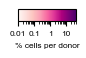

In [54]:
fig_cbar, ax_cbar = plt.subplots(figsize=(0.75, 0.15))
cb = plt.colorbar(plt.cm.ScalarMappable(norm=LogNorm(vmin=vmin, vmax=vmax), cmap=cmap), cax=ax_cbar,
                  orientation="horizontal")
cb.set_label("% cells per donor", fontsize=FS)
xticks = [t for t in [0.01, 0.1, 1, 10, 50] if t <= vmax]
cb.ax.set_xticks(xticks, [str(t) for t in xticks], fontsize=FS)
cb.ax.set_xlim([vmin, vmax])
savefig("stats_cells_celltype_donor_colorbar")
plt.show()

### Number of cells per cytokine (exp_1)

PBS cells are split by their well (`bc1_well`), as in `01_umap.ipynb`; platelets are excluded.

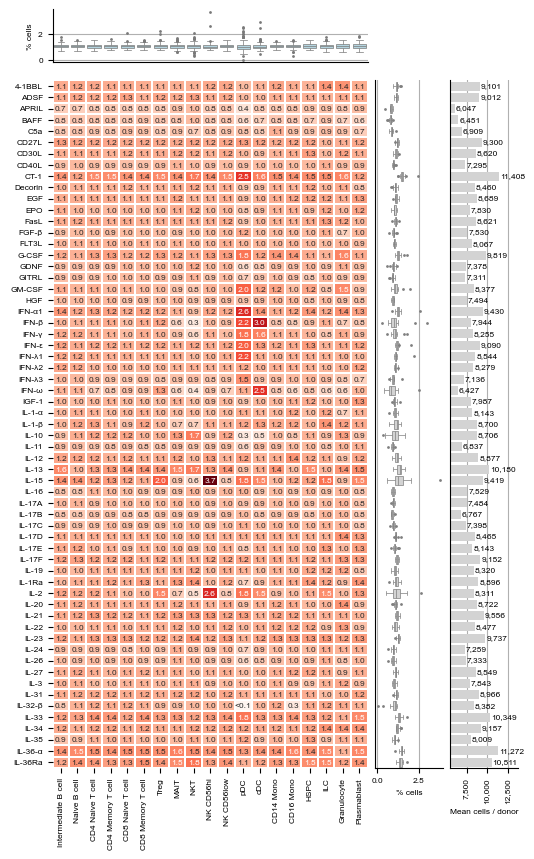

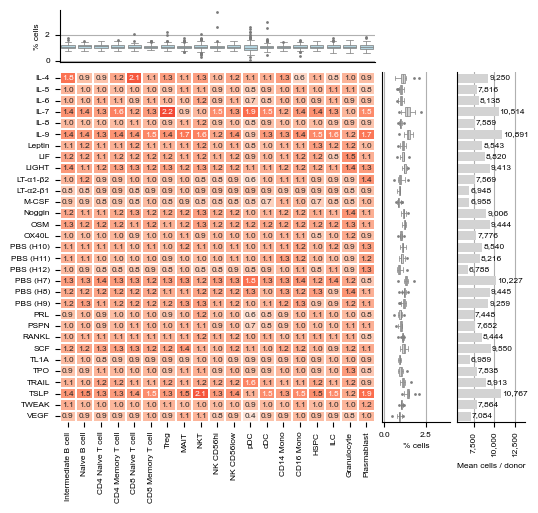

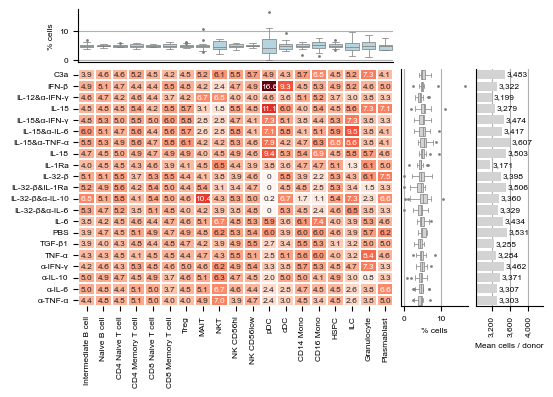

In [74]:
def annot_fn2(x):
    if x > 0.1:
        return f"{x:.1f}"
    elif x > 0.01:
        return "<0.1"
    elif x > 0:
        return "<0.01"
    return "0"

df_bio = pd.read_excel(CYTOKINE_INFO, sheet_name="all_cytokines")
cytokine_to_family = dict(zip(df_bio.name, df_bio.DEG_plot_family))
replacement_cytokines = ["C3a", "IL-18", "TNF-alpha", "TGF-beta1"]
SCREEN_COLORS = {"Main": "#4C87C6", "Follow-up": "#F57F20"}
panel_family_colors = {**FAMILY_COLORS, "Antibody": "#666666", "Combination": "#000000"}

# Aggregate before constructing labels to avoid creating millions of strings.
condition_counts = obs.groupby(["experiment", "timepoint", "treatment", "cytokine", "bc1_well", "cell_type"], observed=True).size().rename("count").reset_index()
keep = condition_counts.timepoint.eq("24h") & condition_counts.cell_type.ne("Platelet")
keep &= (condition_counts.experiment.eq("exp_1") & ~condition_counts.cytokine.isin(replacement_cytokines)) | condition_counts.experiment.eq("exp_2")
condition_counts = condition_counts.loc[keep].copy()
condition_counts["screen"] = condition_counts.experiment.astype(str).map({"exp_1": "Main", "exp_2": "Follow-up"})

# Distinguish PBS wells and conditions from the two screens.
cytokines = condition_counts.cytokine.astype(str)
labels = np.where(cytokines.eq("PBS"), "PBS (" + condition_counts.bc1_well.astype(str) + ")", cytokines)
condition_counts["cyto2"] = [replace_greek(label) for label in labels]
condition_counts["cyto2"] += np.where(condition_counts.screen.eq("Follow-up"), " [follow-up]", "")

# Preserve cytokine-family colors; give antibodies and combinations their own colors.
fallback_family = condition_counts.treatment.astype(str).map({"PBS": "PBS", "antibody": "Antibody", "combination": "Combination"})
condition_counts["family"] = cytokines.map(cytokine_to_family).fillna(fallback_family)
assert condition_counts.family.isin(panel_family_colors).all()

num_cells_per_cytokine = condition_counts.groupby(["cyto2", "family", "screen"], observed=True)["count"].sum().reset_index()
condition_meta = num_cells_per_cytokine.set_index("cyto2")[["family", "screen"]]
counts = condition_counts.groupby(["cyto2", "cell_type"], observed=True)["count"].sum().unstack("cell_type", fill_value=0)

df_pivot = counts.div(counts.sum(axis=0), axis=1) * 100
cytokine_order = sorted(df_pivot.index, key=str.casefold)
celltype_order = [c for c in CELLTYPE_ORDER if c in df_pivot.columns]
df_pivot = df_pivot.loc[cytokine_order, celltype_order]
df_annot = df_pivot.map(annot_fn2)
long = df_pivot.stack().rename("frac_per_celltype").reset_index().join(condition_meta, on="cyto2")


def cytokine_panel(conditions, name, df_pivot, df_annot, long, num_cells_per_cytokine, cmap="Reds", count_label="# cells", row_height=0.15):
    top_height = 0.7
    heatmap_height = row_height * len(conditions)

    fig, ax = plt.subplots(2, 3, figsize=(6, top_height + heatmap_height), height_ratios=[top_height, heatmap_height], width_ratios=[0.7, 0.15, 0.15], gridspec_kw={"hspace": 0.05, "wspace": 0.05})
    ax_top, ax_hm, ax_box, ax_bar = ax[0, 0], ax[1, 0], ax[1, 1], ax[1, 2]
    for a in (ax[0, 1], ax[0, 2]):
        a.set_axis_off()

    sns.boxplot(data=long, x="cell_type", y="frac_per_celltype", order=df_pivot.columns, linewidth=0.5, fliersize=1, ax=ax_top, color="lightblue")
    ax_top.grid(True)
    ax_top.set_xticks([])
    ax_top.set_xlabel("")
    ax_top.set_ylabel("% cells", fontsize=FS)
    ax_top.tick_params(labelsize=FS)
    ax_top.spines[["right", "top"]].set_visible(False)

    sub = df_pivot.loc[conditions]
    sns.heatmap(sub, annot=df_annot.loc[conditions], annot_kws={"fontsize": FS}, fmt="", cbar=None, ax=ax_hm,
                cmap=cmap, linecolor="white", linewidth=0.25,
                vmin=df_pivot.min().min(), vmax=df_pivot.max().max())
    ax_hm.set_xlabel("")
    ax_hm.set_ylabel("")
    ax_hm.set_yticks(0.5 + np.arange(sub.shape[0]), sub.index, fontsize=FS)
    ax_hm.set_xticks(0.5 + np.arange(sub.shape[1]), sub.columns, fontsize=FS, rotation=90)

    sub_long = long[long.cyto2.isin(conditions)]
    sns.boxplot(data=sub_long, x="frac_per_celltype", y="cyto2", order=conditions, color="lightgray", linewidth=0.5, fliersize=1, ax=ax_box)
    ax_box.grid(True)
    ax_box.set_yticks([])
    ax_box.set_ylabel("")
    ax_box.set_xlabel("% cells", fontsize=FS)
    ax_box.tick_params(labelsize=FS)
    ax_box.set_xlim(ax_top.get_ylim())
    ax_box.spines[["right", "top"]].set_visible(False)

    sns.barplot(data=num_cells_per_cytokine, y="cyto2", x="count", order=conditions, color="lightgray", ax=ax_bar)
    ax_bar.set_axisbelow(True)
    ax_bar.grid(True)
    ax_bar.set_yticks([])
    ax_bar.set_ylabel("")
    ax_bar.set_xlabel(count_label, fontsize=FS)
    lo, hi = num_cells_per_cytokine["count"].min(), num_cells_per_cytokine["count"].max()
    ax_bar.set_xlim(0.9 * lo, 1.2 * hi)
    ax_bar.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4))
    ax_bar.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax_bar.tick_params(axis="x", labelsize=FS, rotation=90)
    ax_bar.spines[["right", "top"]].set_visible(False)
    for p in ax_bar.patches:
        if p.get_width() > 0:
            ax_bar.text(p.get_width() + 0.01 * hi, p.get_y() + p.get_height() / 2., f"{p.get_width():,.0f}",
                        ha="left", va="center", fontsize=FS)
    savefig(name)
    plt.show()

from utils.unicode_utils import introduce_greek_letters


# Same formatting as Notebook 4.
def format_treatment(treat, connection="&"):
    return introduce_greek_letters(treat.replace("_", connection).replace("AB", "alpha"))


# Retain donor identities when aggregating.
condition_counts = obs.groupby(["experiment", "timepoint", "cytokine", "bc1_well", "donor", "cell_type"], observed=True).size().rename("count").reset_index()
replacement_cytokines = ["C3a", "IL-18", "TNF-alpha", "TGF-beta1"]

for experiment, screen in [("exp_1", "main"), ("exp_2", "followup")]:
    keep = condition_counts.experiment.eq(experiment) & condition_counts.timepoint.eq("24h") & condition_counts.cell_type.ne("Platelet")
    if experiment == "exp_1":
        keep &= ~condition_counts.cytokine.isin(replacement_cytokines)
    data = condition_counts.loc[keep].copy()

    cytokines = data.cytokine.astype(str)
    labels = np.where(cytokines.eq("PBS"), "PBS (" + data.bc1_well.astype(str) + ")", cytokines) if experiment == "exp_1" else cytokines
    data["cyto2"] = [format_treatment(label) for label in labels]

    counts = data.groupby(["cyto2", "cell_type"], observed=True)["count"].sum().unstack("cell_type", fill_value=0)

    # Count donors per condition, across all cell types.
    n_donors = data.groupby("cyto2", observed=True).donor.nunique()
    # plot_counts = counts.div(n_donors, axis=0) if experiment == "exp_2" else counts
    plot_counts = counts.div(n_donors, axis=0)
    num_cells_per_cytokine = plot_counts.sum(axis=1).rename("count").reset_index()

    # Normalize separately within each screen.
    df_pivot = plot_counts.div(plot_counts.sum(axis=0), axis=1) * 100
    cytokine_order = sorted(df_pivot.index, key=str.casefold)
    celltype_order = [c for c in CELLTYPE_ORDER if c in df_pivot.columns]
    df_pivot = df_pivot.loc[cytokine_order, celltype_order]
    df_annot = df_pivot.map(annot_fn2)
    long = df_pivot.stack().rename("frac_per_celltype").reset_index()

    # Two main-screen panels, one follow-up panel.
    split = round(2 * len(cytokine_order) / 3)
    parts = [cytokine_order[:split], cytokine_order[split:]] if experiment == "exp_1" else [cytokine_order]
    #count_label = "Mean cells / donor" if experiment == "exp_2" else "# cells"
    count_label = "Mean cells / donor"

    for part, conditions in enumerate(parts, start=1):
        name = f"stats_cytokine_distribution_main_{part}" if experiment == "exp_1" else "stats_cytokine_distribution_followup"
        cytokine_panel(list(conditions), name, df_pivot, df_annot, long, num_cells_per_cytokine, count_label=count_label)

### Cell type composition per donor (coarse cell types)

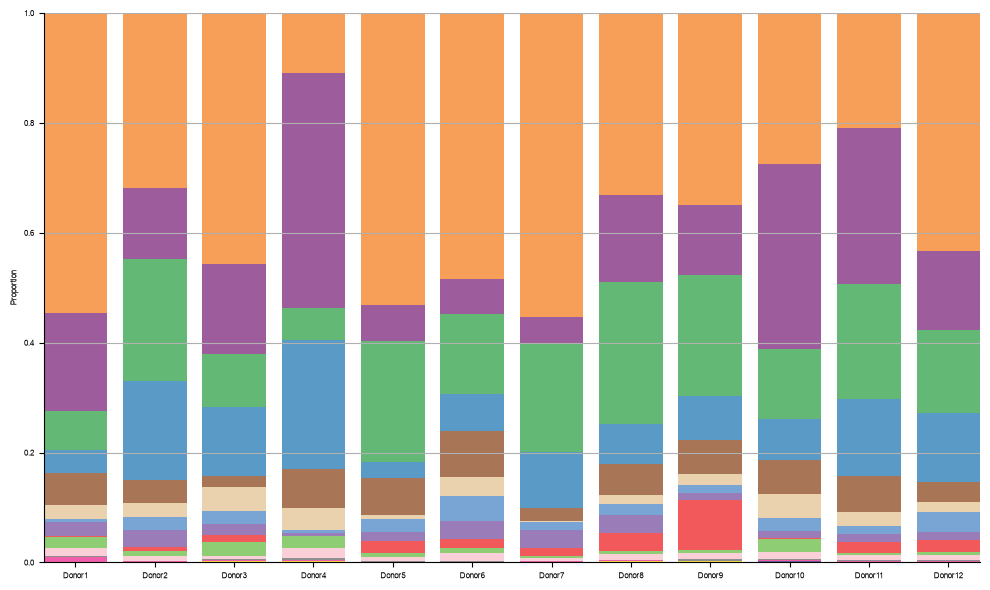

In [24]:
df_total_per_donor = STATS.donor.value_counts()
df_celltype_per_donor = (STATS.groupby("donor", observed=True).cell_type_coarse.value_counts()
                         .rename("count").reset_index())
df_celltype_per_donor = df_celltype_per_donor[df_celltype_per_donor["count"] > 0]
df_celltype_per_donor["celltype_fraction"] = (100 * df_celltype_per_donor["count"]
                                              / df_celltype_per_donor["donor"].map(df_total_per_donor).astype(float))
df_celltype_per_donor["donor"] = df_celltype_per_donor["donor"].astype(str)
df_celltype_per_donor["cell_type_coarse"] = df_celltype_per_donor["cell_type_coarse"].astype(str)
celltypes_by_mean = (df_celltype_per_donor.groupby("cell_type_coarse")["celltype_fraction"].mean()
                     .sort_values(ascending=False))

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
_df = STATS[["donor", "cell_type_coarse"]].astype(str)
_df["donor"] = pd.Categorical(_df["donor"], categories=DONOR_ORDER)   # x axis in donor order
sns.histplot(data=_df, x="donor", hue="cell_type_coarse", stat="proportion", multiple="fill", discrete=True,
             shrink=.8, palette=celltype_color_mapping, linewidth=0., hue_order=list(celltypes_by_mean.index),
             legend=False, ax=ax)
ax.spines[["right", "top"]].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel(ax.get_ylabel(), fontsize=FS)
ax.grid(axis="y")
ax.tick_params(labelsize=FS)
plt.tight_layout()
savefig("stats_composition_per_donor_fill")
plt.show()

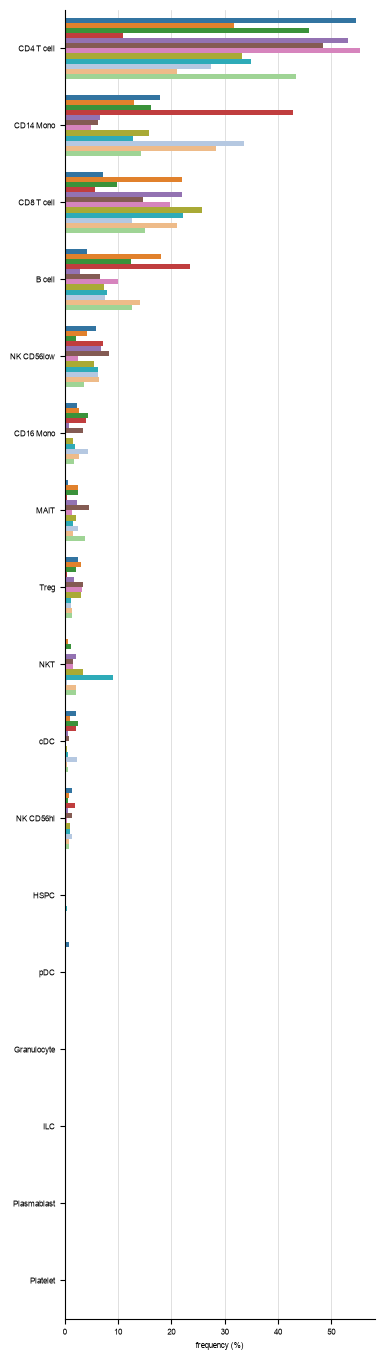

In [25]:
def composition_barplot(celltypes, figsize, name, horizontal=True, log=False):
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    xy = dict(y="cell_type_coarse", x="celltype_fraction") if horizontal else dict(x="cell_type_coarse", y="celltype_fraction")
    sns.barplot(df_celltype_per_donor, **xy, hue="donor", hue_order=DONOR_ORDER, palette=DONOR_COLORS,
                legend=False, order=list(celltypes), ax=ax)
    ax.grid(axis="x" if horizontal else "y", linewidth=0.5, color="lightgray")
    ax.set_axisbelow(True)
    ax.spines[["right", "top"]].set_visible(False)
    (ax.set_xlabel if horizontal else ax.set_ylabel)("frequency (%)", fontsize=FS)
    (ax.set_ylabel if horizontal else ax.set_xlabel)("")
    if log:
        ax.set_yscale("log")
    ax.tick_params(labelsize=FS)
    if name:
        savefig(name)
    plt.show()


composition_barplot(celltypes_by_mean.index, (4, 17), "stats_composition_per_donor")

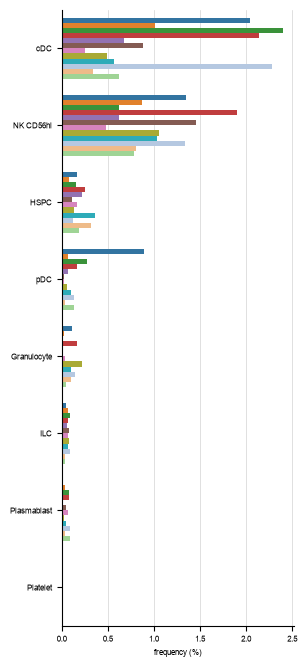

In [26]:
composition_barplot(celltypes_by_mean[celltypes_by_mean < 2].index, (3, 8), "stats_composition_per_donor_rare")

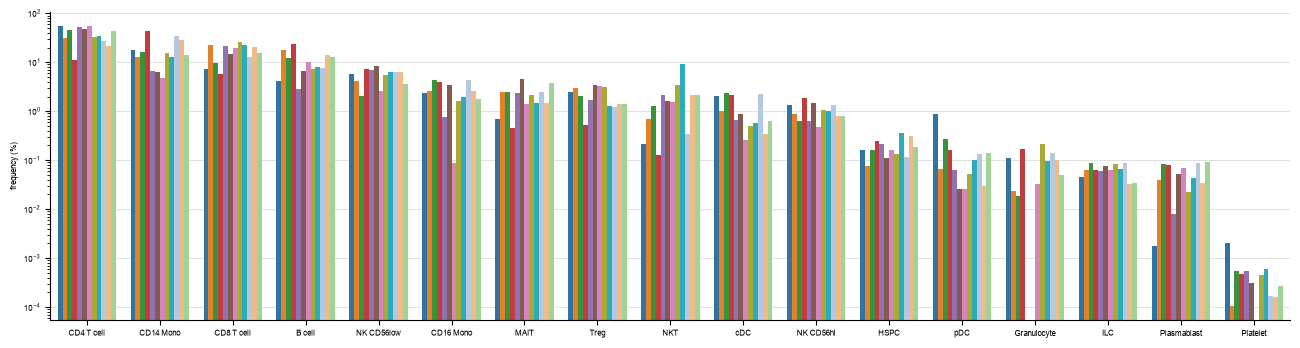

<Figure size 10x10 with 0 Axes>

In [27]:
composition_barplot(celltypes_by_mean.index, (16, 4), None, horizontal=False, log=True)
fig_l = legend_figure({donor_label(d): DONOR_COLORS[d] for d in DONOR_ORDER}, "Donor")
save(fig_l, "stats_donor_legend")
plt.show()